# Spacecraft Telemetry: EDA and Statistical Baselines

This notebook records the exploratory analysis and statistical baselines tried so far on the NASA/JPL **SMAP** and **MSL** telemetry data.

The main goals are to:

- understand the dataset and the anomaly labels;
- look at examples of **point** and **contextual** anomalies;
- try five simple statistical anomaly-detection baselines;
- compare them using the same evaluation metrics across all 82 channels.

The results here are **preliminary**. They are meant to give the group a clear reference point for later model comparisons.


## 1. Setup and load the data

The Kaggle copy of the dataset contains one training array and one test array for each telemetry channel, plus a CSV file with the labeled anomaly intervals.

For this baseline analysis, only the **first column** of each NumPy array is used as the telemetry signal. The remaining columns contain command/context information and are not used yet.


In [19]:
# Install KaggleHub package
%pip install -q kagglehub


Note: you may need to restart the kernel to use updated packages.


In [20]:
import ast
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

# Download / locate the dataset
base_path = kagglehub.dataset_download(
    "patrickfleith/nasa-anomaly-detection-dataset-smap-msl"
)

labels_path = os.path.join(base_path, "labeled_anomalies.csv")
labels = pd.read_csv(labels_path)

print("Dataset path:", base_path)
print("Labels shape:", labels.shape)


Dataset path: /Users/jezercahodaj/.cache/kagglehub/datasets/patrickfleith/nasa-anomaly-detection-dataset-smap-msl/versions/1
Labels shape: (82, 5)


### Dataset summary

- There are **82 telemetry channels**: 55 from SMAP and 27 from MSL.
- A channel can contain point-type anomaly intervals, contextual anomaly intervals, or a mixture of both.
- The shaded regions in the plots below are the **labeled anomaly intervals given in the dataset**.


In [21]:
def parse_intervals(x):
    return ast.literal_eval(x) if isinstance(x, str) else x


def parse_classes(x):
    if isinstance(x, list):
        return x

    text = str(x).strip()
    try:
        values = ast.literal_eval(text)
        if isinstance(values, list):
            return [str(v).strip() for v in values]
    except Exception:
        pass

    return [
        item.strip().strip("'\"")
        for item in text.strip("[]").split(",")
        if item.strip()
    ]


def channel_anomaly_type(x):
    classes = parse_classes(x)
    unique = set(classes)
    if unique == {"point"}:
        return "point"
    if unique == {"contextual"}:
        return "contextual"
    return "mixed"

labels["intervals"] = labels["anomaly_sequences"].apply(parse_intervals)
labels["anomaly_type"] = labels["class"].apply(channel_anomaly_type)

print("Number of channels:", len(labels))
print(labels["spacecraft"].value_counts())
print("\nChannel-level anomaly type:")
print(labels["anomaly_type"].value_counts())


Number of channels: 82
spacecraft
SMAP    55
MSL     27
Name: count, dtype: int64

Channel-level anomaly type:
anomaly_type
point         52
contextual    26
mixed          4
Name: count, dtype: int64


## 2. Two example channels

The two channels below show why one anomaly score may not work equally well everywhere.

- **P-1** has three labeled **contextual** anomaly intervals. The values are not always globally extreme; the unusual behavior is related to the local pattern over time.
- **S-1** has one labeled **point-type** anomaly interval. In this channel, unusually high or low values are more informative.


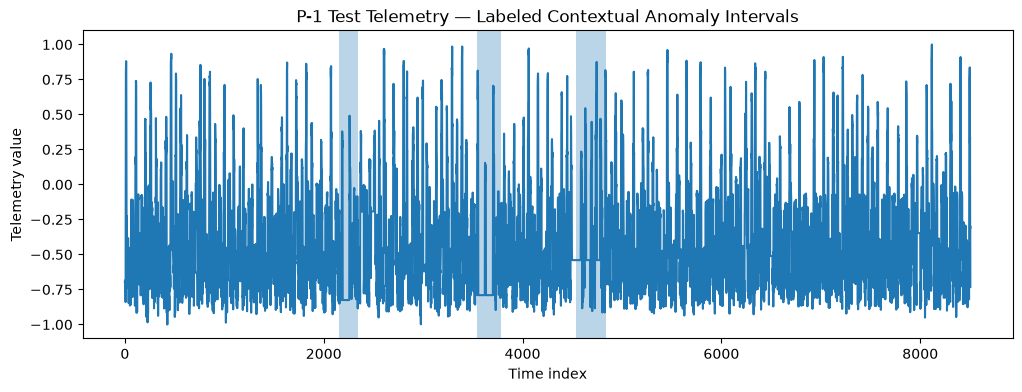

In [22]:
def load_signal(channel):
    train = np.load(
        os.path.join(base_path, "data", "data", "train", f"{channel}.npy")
    )[:, 0]
    test = np.load(
        os.path.join(base_path, "data", "data", "test", f"{channel}.npy")
    )[:, 0]
    return train, test

p1_train, p1_test = load_signal("P-1")
p1_intervals = [[2149, 2349], [3539, 3779], [4536, 4844]]

plt.figure(figsize=(12, 4))
plt.plot(p1_test)
for start, end in p1_intervals:
    plt.axvspan(start, end, alpha=0.3)
plt.xlabel("Time index")
plt.ylabel("Telemetry value")
plt.title("P-1 Test Telemetry — Labeled Contextual Anomaly Intervals")
plt.show()


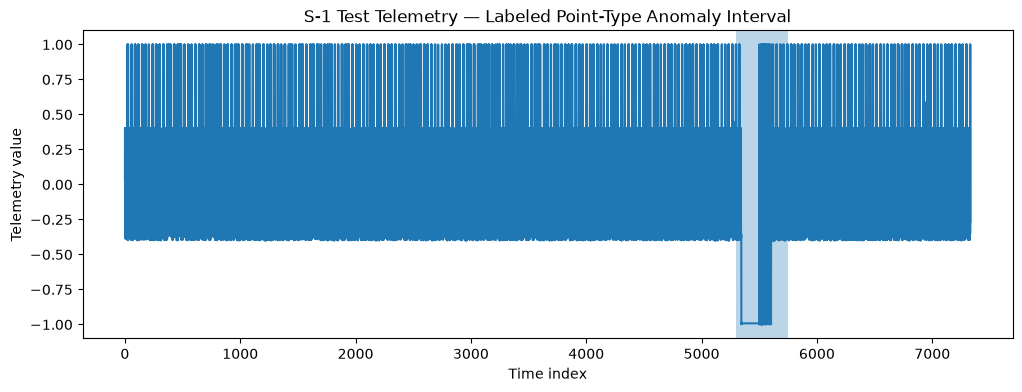

In [23]:
s1_train, s1_test = load_signal("S-1")
s1_intervals = [[5300, 5747]]

plt.figure(figsize=(12, 4))
plt.plot(s1_test)
plt.axvspan(5300, 5747, alpha=0.3)
plt.xlabel("Time index")
plt.ylabel("Telemetry value")
plt.title("S-1 Test Telemetry — Labeled Point-Type Anomaly Interval")
plt.show()


### What these examples show

- P-1 has **3 anomaly intervals** and S-1 has **1 anomaly interval**.
- An interval can contain many time points. For example, the S-1 interval 5300–5747 contains 448 points.


## 3. Evaluation metrics

Each test point is labeled as either anomalous or normal. From that comparison we calculate:

$$
\text{Precision}=\frac{TP}{TP+FP}
$$

Precision asks: **when the method gives an alert, how often is it right?**

$$
\text{Recall}=\frac{TP}{TP+FN}
$$

Recall asks: **how much of the labeled anomaly did the method find?**

$$
F1=2\frac{\text{Precision}\times\text{Recall}}{\text{Precision}+\text{Recall}}
$$

F1 balances precision and recall.

We also use:

- **Event recall:** an anomaly interval counts as detected if at least one point inside it is flagged.
- **False alarms per 1000 normal points:**

$$
1000\times\frac{FP}{FP+TN}
$$

Event recall is useful, but it should always be looked at together with false alarms because a method that flags too many points can detect an event by chance.


In [24]:
def calculate_metrics(pred, truth):
    TP = np.sum(pred & truth)
    FP = np.sum(pred & ~truth)
    FN = np.sum(~pred & truth)
    TN = np.sum(~pred & ~truth)

    precision = TP / (TP + FP) if TP + FP > 0 else 0
    recall = TP / (TP + FN) if TP + FN > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


## 4. Statistical baselines

All methods use the **training data** to define what looks normal. Test anomaly labels are not used to choose the thresholds.

For the score-based methods, the cutoff is the **99th percentile of the training anomaly scores**. The rank method instead uses the most extreme 0.5% in either tail of the empirical training distribution.


### Baseline 1: Global z-score

The global z-score compares a test value with the overall training mean and standard deviation:

$$
z_t=\frac{x_t-\mu_{\text{train}}}{\sigma_{\text{train}}}
$$

The anomaly score is $|z_t|$.

- Large scores mean the value is far from the usual training level.
- This method is simple, but it does **not** consider the recent values before it.


In [25]:
def global_z_predictions(train_signal, test_signal):
    mean = train_signal.mean()
    std = train_signal.std()

    if std < 1e-12:
        return np.zeros(len(test_signal), dtype=bool)

    train_scores = np.abs((train_signal - mean) / std)
    threshold = np.percentile(train_scores, 99)
    test_scores = np.abs((test_signal - mean) / std)

    return test_scores > threshold


### Baseline 2: Two-sided empirical rank

This method does not assume a Normal distribution. It asks where the current value falls compared with the observed training values.

$$
p_t=\hat F_{\text{train}}(x_t)
$$

Here, $\hat F_{\text{train}}$ is the **empirical CDF**: the proportion of training values less than or equal to $x_t$.

A point is flagged when it falls in an extreme tail:

$$
p_t\le 0.005 \quad \text{or} \quad p_t\ge 0.995
$$

- This is useful when anomalies are unusually high or low compared with the whole training distribution.
- Many repeated values can create ties, which makes ranking less informative on some channels.


In [26]:
def rank_predictions(train_signal, test_signal):
    sorted_train = np.sort(train_signal)
    n_train = len(sorted_train)

    left = np.searchsorted(sorted_train, test_signal, side="left")
    right = np.searchsorted(sorted_train, test_signal, side="right")

    # Mid-rank handles tied values
    percentile = ((left + right) / 2) / n_train

    return (percentile <= 0.005) | (percentile >= 0.995)


### Baseline 3: Rolling z-score

Instead of comparing the current value with the whole training distribution, the rolling z-score compares it with the **previous $w$ observations**:

$$
z_t^{(\mathrm{roll})}
=
\frac{x_t-\bar{x}_{t,w}}{s_{t,w}}
$$

where $\bar{x}_{t,w}$ and $s_{t,w}$ are the mean and standard deviation of the previous window.

For this exploratory analysis, I used **$w=50$**.

- The current point is not included in its own baseline.
- A small lower bound is used for the rolling standard deviation so that nearly flat windows do not create division-by-zero problems.
- $w=50$ was a practical starting value, not an optimized choice. It was not tuned using the test labels.


In [27]:
def rolling_z_predictions(train_signal, test_signal, window=50):
    global_std = train_signal.std()
    min_std = max(0.01 * global_std, 1e-8)

    # Training scores
    train_series = pd.Series(train_signal)
    train_mean = train_series.shift(1).rolling(window).mean()
    train_std = train_series.shift(1).rolling(window).std(ddof=0).clip(lower=min_std)
    train_scores = np.abs((train_series - train_mean) / train_std)
    valid_train_scores = train_scores[np.isfinite(train_scores)]

    if len(valid_train_scores) == 0:
        return np.zeros(len(test_signal), dtype=bool)

    threshold = np.percentile(valid_train_scores, 99)

    # Test scores
    test_series = pd.Series(test_signal)
    test_mean = test_series.shift(1).rolling(window).mean()
    test_std = test_series.shift(1).rolling(window).std(ddof=0).clip(lower=min_std)
    test_scores = np.abs((test_series - test_mean) / test_std)

    return (test_scores > threshold).fillna(False).to_numpy()


### Baseline 4: Global robust z-score using median and MAD

MAD stands for **Median Absolute Deviation**:

$$
MAD=\operatorname{median}\left(|x_i-\operatorname{median}(x)|\right)
$$

The robust score is

$$
r_t
=
\left|
0.6745\frac{x_t-\operatorname{median}(x_{\text{train}})}{MAD_{\text{train}}}
\right|
$$

- The median and MAD are less affected by extreme values than the mean and standard deviation.
- This is useful when we are dealing with skewed distributions.
- Some channels have many repeated values, which can still make the threshold less useful.


In [28]:
def robust_z_predictions(train_signal, test_signal):
    train_median = np.median(train_signal)
    train_mad = np.median(np.abs(train_signal - train_median))

    if train_mad < 1e-12:
        return np.zeros(len(test_signal), dtype=bool)

    train_scores = np.abs(
        0.6745 * (train_signal - train_median) / train_mad
    )
    threshold = np.percentile(train_scores, 99)

    test_scores = np.abs(
        0.6745 * (test_signal - train_median) / train_mad
    )

    return test_scores > threshold


### Baseline 5: Rolling median/MAD

This method combines local time context with robust statistics.

The rolling median is

$$
m_t=\operatorname{median}(x_{t-w},\ldots,x_{t-1})
$$

The rolling MAD is

$$
MAD_t
=
\operatorname{median}_{i=t-w,\ldots,t-1}|x_i-m_t|
$$

The anomaly score is

$$
s_t
=
\left|
0.6745\frac{x_t-m_t}{MAD_t}
\right|
$$

Again, **$w=50$** is used as an exploratory window size.

- The current point is compared with the recent local median.
- MAD gives a local measure of how much the recent values vary.
- A small lower bound is used when the rolling MAD is very close to zero.


In [29]:
def rolling_mad_predictions(train_signal, test_signal, window=50):
    train_series = pd.Series(train_signal)

    train_median = train_series.shift(1).rolling(window).median()
    train_mad = train_series.shift(1).rolling(window).apply(
        lambda x: np.median(np.abs(x - np.median(x))),
        raw=True,
    )

    global_median = np.median(train_signal)
    global_mad = np.median(np.abs(train_signal - global_median))
    min_mad = max(0.01 * global_mad, 1e-8)

    train_mad_safe = train_mad.clip(lower=min_mad)
    train_scores = np.abs(
        0.6745 * (train_series - train_median) / train_mad_safe
    )
    valid_train_scores = train_scores[np.isfinite(train_scores)]

    if len(valid_train_scores) == 0:
        return np.zeros(len(test_signal), dtype=bool)

    threshold = np.percentile(valid_train_scores, 99)

    test_series = pd.Series(test_signal)
    test_median = test_series.shift(1).rolling(window).median()
    test_mad = test_series.shift(1).rolling(window).apply(
        lambda x: np.median(np.abs(x - np.median(x))),
        raw=True,
    )
    test_mad_safe = test_mad.clip(lower=min_mad)

    test_scores = np.abs(
        0.6745 * (test_series - test_median) / test_mad_safe
    )

    return (test_scores > threshold).fillna(False).to_numpy()


## 5. Apply all five baselines to all 82 channels

The same steps are used for every channel:

1. load the training and test telemetry signal;
2. build the Boolean truth vector from the labeled anomaly intervals;
3. run all five baseline methods;
4. calculate point-level precision, recall, and F1;
5. calculate event recall and false alarms per 1000 normal points.

All five methods were tested in the same way, using the same code for the labels and the same performance metrics.


In [30]:
methods = {
    "global_z": global_z_predictions,
    "robust_z": robust_z_predictions,
    "rank_two_sided": rank_predictions,
    "rolling_z": lambda tr, te: rolling_z_predictions(tr, te, window=50),
    "rolling_mad": lambda tr, te: rolling_mad_predictions(tr, te, window=50),
}

results_list = []

for _, row in labels.iterrows():
    channel = row["chan_id"]
    spacecraft = row["spacecraft"]
    intervals = row["intervals"]
    anomaly_type = row["anomaly_type"]

    train_signal, test_signal = load_signal(channel)

    truth = np.zeros(len(test_signal), dtype=bool)
    for start, end in intervals:
        truth[start:end + 1] = True

    for method_name, method_fn in methods.items():
        pred = method_fn(train_signal, test_signal)
        metrics = calculate_metrics(pred, truth)

        event_hits = sum(
            pred[start:end + 1].any()
            for start, end in intervals
        )
        n_events = len(intervals)
        event_recall = event_hits / n_events if n_events else np.nan

        FP = metrics["FP"]
        TN = metrics["TN"]
        false_alarm_rate = FP / (FP + TN) if (FP + TN) > 0 else np.nan

        results_list.append({
            "channel": channel,
            "spacecraft": spacecraft,
            "anomaly_type": anomaly_type,
            "method": method_name,
            "n_events": n_events,
            "events_detected": event_hits,
            "event_recall": event_recall,
            "n_flagged": int(pred.sum()),
            **metrics,
            "false_alarms_per_1000": false_alarm_rate * 1000,
        })

results_all = pd.DataFrame(results_list)
print(results_all.shape)
print(results_all["method"].value_counts())


(410, 16)
method
global_z          82
robust_z          82
rank_two_sided    82
rolling_z         82
rolling_mad       82
Name: count, dtype: int64


## 6. Results across all channels

The table below shows both the **mean** and **median** across the 82 channels.

The median is useful here because performance varies a lot from one channel to another. A few very large false-alarm rates can pull the mean upward.


In [31]:
overall_summary = (
    results_all
    .groupby("method")[[
        "precision",
        "recall",
        "f1",
        "event_recall",
        "false_alarms_per_1000",
    ]]
    .agg(["mean", "median"])
    .round(3)
)

overall_summary


precision        recall            f1        event_recall  \
                    mean median   mean median   mean median         mean   
method                                                                     
global_z           0.313  0.013  0.185  0.003  0.141  0.006        0.524   
rank_two_sided     0.410  0.224  0.346  0.094  0.219  0.062        0.734   
robust_z           0.202  0.000  0.155  0.000  0.099  0.000        0.390   
rolling_mad        0.467  0.361  0.125  0.051  0.138  0.073        0.730   
rolling_z          0.360  0.240  0.129  0.027  0.134  0.040        0.972   

                      false_alarms_per_1000         
               median                  mean median  
method                                              
global_z          1.0                54.969  0.064  
rank_two_sided    1.0               153.446  7.011  
robust_z          0.0                60.033  0.000  
rolling_mad       1.0                21.278  1.758  
rolling_z         1.0                23.903  9.627

### Mean F1 by anomaly type

This plot compares point-level F1 separately for point, contextual, and mixed channels.


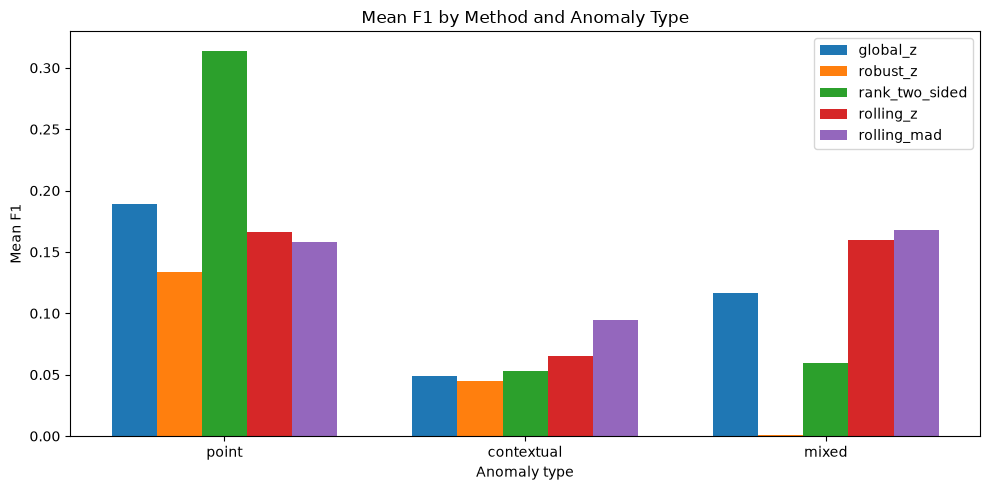

In [32]:
method_order = [
    "global_z",
    "robust_z",
    "rank_two_sided",
    "rolling_z",
    "rolling_mad",
]
anomaly_order = ["point", "contextual", "mixed"]

plot_summary = (
    results_all
    .groupby(["anomaly_type", "method"])[["f1", "event_recall"]]
    .mean()
    .reset_index()
)

f1_matrix = []
for anomaly in anomaly_order:
    row = []
    for method in method_order:
        value = plot_summary.loc[
            (plot_summary["anomaly_type"] == anomaly)
            & (plot_summary["method"] == method),
            "f1",
        ].values[0]
        row.append(value)
    f1_matrix.append(row)

f1_matrix = np.array(f1_matrix)
x = np.arange(len(anomaly_order))
width = 0.15

plt.figure(figsize=(10, 5))
for i, method in enumerate(method_order):
    plt.bar(x + (i - 2) * width, f1_matrix[:, i], width=width, label=method)

plt.xticks(x, anomaly_order)
plt.ylabel("Mean F1")
plt.xlabel("Anomaly type")
plt.title("Mean F1 by Method and Anomaly Type")
plt.legend()
plt.tight_layout()
plt.show()


### Mean event recall by anomaly type

Event recall only asks whether each labeled anomaly interval was detected at least once. It does not measure how much of the interval was found.


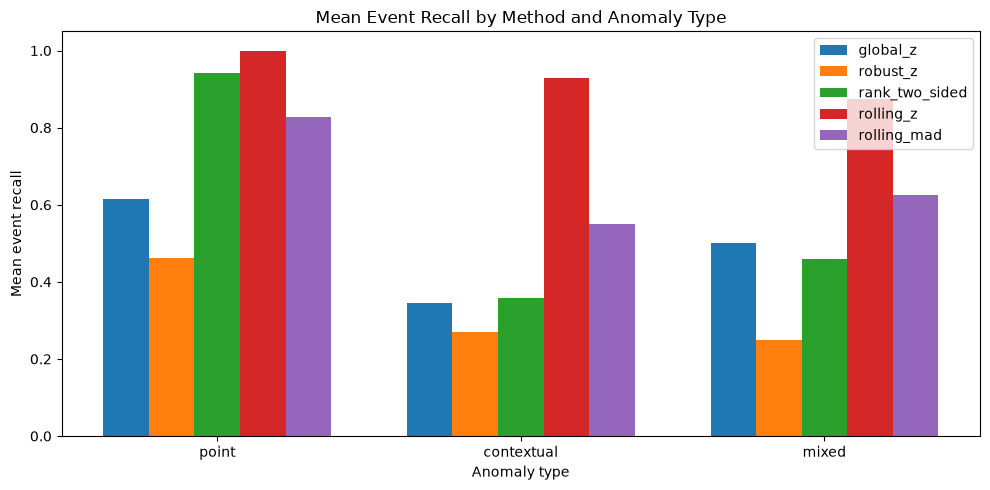

In [33]:
event_matrix = []
for anomaly in anomaly_order:
    row = []
    for method in method_order:
        value = plot_summary.loc[
            (plot_summary["anomaly_type"] == anomaly)
            & (plot_summary["method"] == method),
            "event_recall",
        ].values[0]
        row.append(value)
    event_matrix.append(row)

event_matrix = np.array(event_matrix)

plt.figure(figsize=(10, 5))
for i, method in enumerate(method_order):
    plt.bar(x + (i - 2) * width, event_matrix[:, i], width=width, label=method)

plt.xticks(x, anomaly_order)
plt.ylabel("Mean event recall")
plt.xlabel("Anomaly type")
plt.title("Mean Event Recall by Method and Anomaly Type")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()


### False alarms

False alarms are shown as the number of normal observations incorrectly flagged per 1000 normal observations.

A few channels have very large false-alarm rates, so the distribution is strongly skewed for some methods.


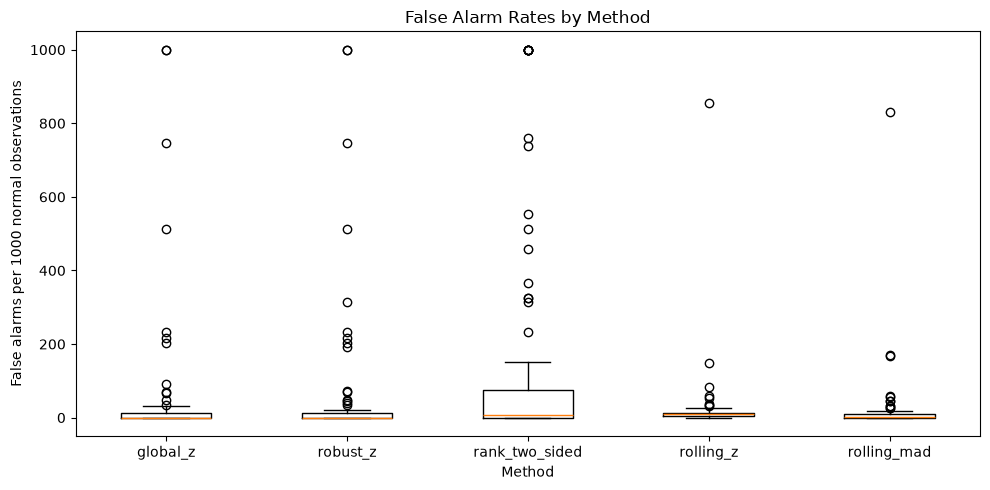

In [38]:
false_alarm_data = [
    results_all.loc[
        results_all["method"] == method,
        "false_alarms_per_1000",
    ].dropna()
    for method in method_order
]

plt.figure(figsize=(10, 5))
plt.boxplot(false_alarm_data, tick_labels=method_order, showfliers=True)
plt.ylabel("False alarms per 1000 normal observations")
plt.xlabel("Method")
plt.title("False Alarm Rates by Method")
plt.tight_layout()
plt.show()


## 7. Two example results

These two examples helped show why the anomaly type matters.

### S-1: point-type anomaly

The two-sided empirical rank method gave:

- precision: **0.610**
- recall: **0.551**
- F1: **0.579**
- anomaly event detected: **1/1**

For S-1, the anomalous values were shifted toward an extreme part of the overall training distribution, so a global tail-based method was useful.

### P-1: contextual anomalies

The rolling median/MAD method gave:

- precision: **0.736**
- recall: **0.137**
- F1: **0.231**
- anomaly events detected: **3/3**

For P-1, the local pattern mattered more than whether a value was globally extreme. The rolling robust method worked better than the global methods on this example.


## 8. What I noticed so far

- The **two-sided rank method** had the highest average F1 overall and was especially strong for point-type channels.
- The **rolling z-score** detected almost every labeled anomaly interval, but its point-level F1 was lower. Event recall alone can therefore look better than the full point-level result.
- The **rolling median/MAD** method had fewer false alarms than the rolling z-score on average and worked much better on P-1.
- The **global robust z-score** did not solve every problem. Some channels contain many repeated values, which can make the cutoff less useful.
- Results vary a lot by channel, so both the mean and median are useful summaries.
- The mixed-anomaly group has only **4 channels**, so its averages should be treated cautiously.


## 9. Current limitations / next checks

- Only the first telemetry column is used here. The command/context columns have not been included yet.
- The rolling window **$w=50$** is an exploratory choice. It should be checked against other window sizes using training/validation data rather than test labels.
- The 99th-percentile thresholds are also baseline choices, not optimized thresholds.
- These statistical methods can be used as reference baselines for the machine-learning models, and their scores can also be used as features in some machine-learning approaches.
